# Ejemplo 1. Magnitud y fase de un sistema de primer orden

**Objetivo:** comparar la entrada sinusoidal con la salida en régimen permanente, observando que ambas tienen la misma frecuencia, pero distinta amplitud y fase.

Considere la planta

$$G(s)=\frac{1}{s+1}$$

y la entrada

$$x(t)=2\sin(2t).$$

La frecuencia de excitación es $\omega=2\;\mathrm{rad/s}$. La respuesta en frecuencia de la planta es

$$G(2j)=\frac{1}{1+2j},\qquad |G(2j)|=\frac{1}{\sqrt{5}},\qquad \phi=-\tan^{-1}(2)\approx-63.4^\circ.$$

Así, la salida permanente es

$$\boxed{y_{\mathrm{per}}(t)=\frac{2}{\sqrt{5}}\sin\!\bigl(2t-\tan^{-1}(2)\bigr)\approx0.894\sin(2t-63.4^\circ).}$$

> **Nota:** las funciones trigonométricas de NumPy reciben los ángulos en **radianes**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros del ejemplo
X0 = 2.0                 # amplitud de entrada
omega = 2.0              # frecuencia angular [rad/s]

# G(jω) = 1/(1+jω)
Gjw = 1 / (1 + 1j * omega)
magnitud = np.abs(Gjw)
phi = np.angle(Gjw)      # fase en radianes
Y0 = X0 * magnitud

# Desplazamiento temporal equivalente a la fase (atraso positivo)
retraso = -phi / omega
periodo = 2 * np.pi / omega

print(f"Magnitud |G(jω)| = {magnitud:.4f}")
print(f"Fase φ = {np.degrees(phi):.2f}°")
print(f"Amplitud de la salida Y0 = {Y0:.4f}")
print(f"Período de ambas señales T = {periodo:.4f} s")
print(f"Atraso temporal equivalente Δt = {retraso:.4f} s")


Magnitud |G(jω)| = 0.4472
Fase φ = -63.43°
Amplitud de la salida Y0 = 0.8944
Período de ambas señales T = 3.1416 s
Atraso temporal equivalente Δt = 0.5536 s


## 1. Comparación de la entrada y la salida permanente

En la gráfica, las dos señales oscilan con el mismo período. La salida presenta menor amplitud y sus máximos ocurren después que los máximos de la entrada. Las líneas verticales indican los primeros máximos positivos de cada señal y la flecha indica el atraso temporal correspondiente.

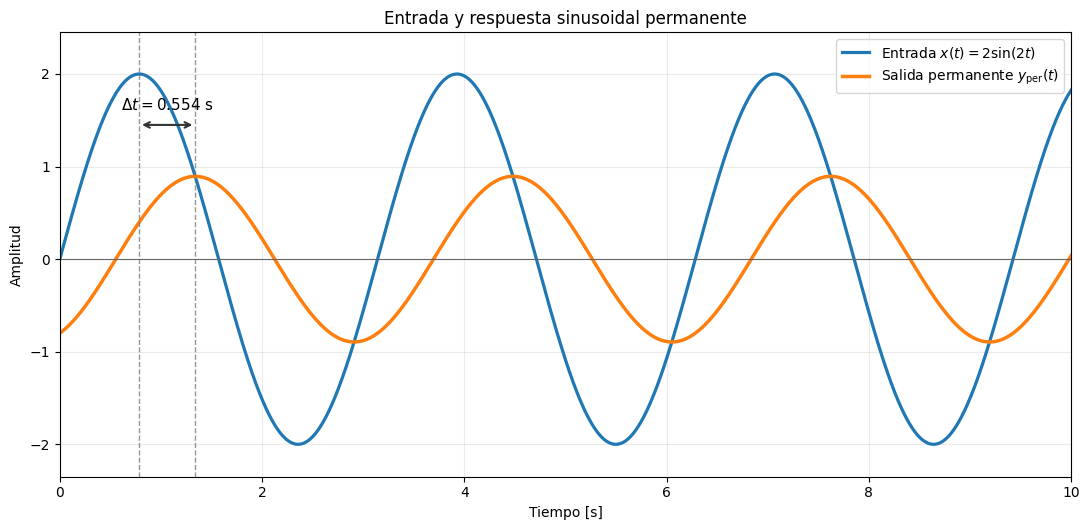

In [2]:
# Generación de las señales
# Se muestran algo más de tres períodos.
t = np.linspace(0, 10, 2000)
x = X0 * np.sin(omega * t)
y_per = Y0 * np.sin(omega * t + phi)

# Instantes del primer máximo positivo
t_max_entrada = np.pi / (2 * omega)
t_max_salida = (np.pi / 2 - phi) / omega

fig, ax = plt.subplots(figsize=(11, 5.4))
ax.plot(t, x, linewidth=2.3, label=r'Entrada $x(t)=2\sin(2t)$')
ax.plot(t, y_per, linewidth=2.5,
        label=r'Salida permanente $y_{\mathrm{per}}(t)$')

# Líneas para visualizar el desplazamiento de fase
ax.axvline(t_max_entrada, color='0.45', ls='--', lw=1.0, alpha=0.75)
ax.axvline(t_max_salida, color='0.45', ls='--', lw=1.0, alpha=0.75)
ax.annotate('', xy=(t_max_salida, 1.45), xytext=(t_max_entrada, 1.45),
            arrowprops=dict(arrowstyle='<->', lw=1.5, color='0.2'))
ax.text((t_max_entrada + t_max_salida) / 2, 1.58,
        rf'$\Delta t={retraso:.3f}\ \mathrm{{s}}$',
        ha='center', va='bottom', fontsize=11)

ax.set_title('Entrada y respuesta sinusoidal permanente')
ax.set_xlabel('Tiempo [s]')
ax.set_ylabel('Amplitud')
ax.set_xlim(0, 10)
ax.set_ylim(-2.35, 2.45)
ax.axhline(0, color='0.4', lw=0.8)
ax.grid(True, alpha=0.25)
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()


## 2. Respuesta completa: transitorio y régimen permanente

**Extensión opcional.** Si la planta parte del reposo, es decir, $y(0)=0$, su salida total es

$$y(t)=\underbrace{0.8e^{-t}}_{y_{\mathrm{tr}}(t)}+\underbrace{\frac{2}{\sqrt{5}}\sin\!\bigl(2t-\tan^{-1}(2)\bigr)}_{y_{\mathrm{per}}(t)}.$$

La componente transitoria $0.8e^{-t}$ decae, y la respuesta total se aproxima a la respuesta permanente.

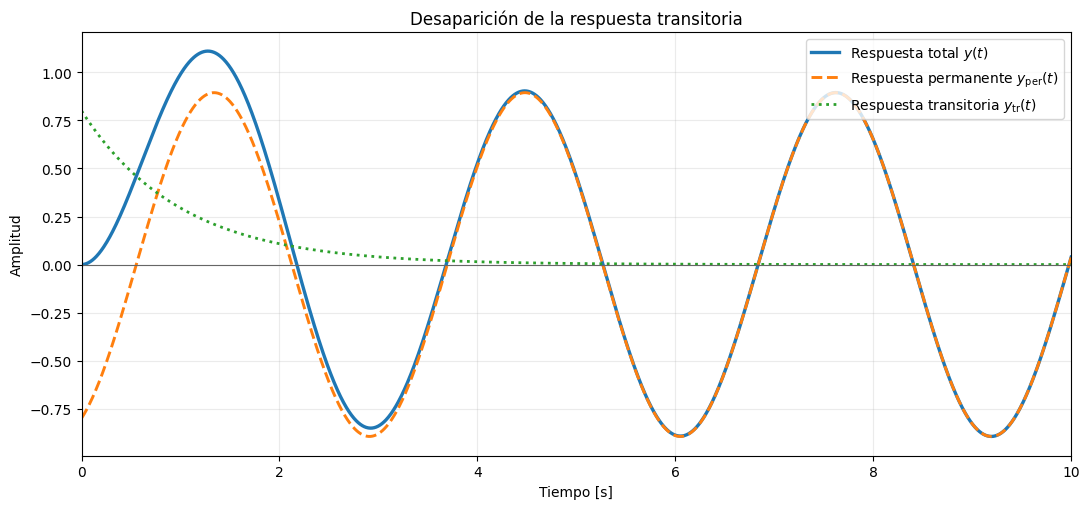

In [3]:
# Para el sistema y'(t) + y(t) = x(t), con y(0)=0:
# la componente transitoria cancela el valor inicial de y_per(t).
y_transitoria = -y_per[0] * np.exp(-t)
y_total = y_per + y_transitoria

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(t, y_total, linewidth=2.4, label='Respuesta total $y(t)$')
ax.plot(t, y_per, '--', linewidth=2.1,
        label=r'Respuesta permanente $y_{\mathrm{per}}(t)$')
ax.plot(t, y_transitoria, ':', linewidth=2.0,
        label=r'Respuesta transitoria $y_{\mathrm{tr}}(t)$')
ax.set_title('Desaparición de la respuesta transitoria')
ax.set_xlabel('Tiempo [s]')
ax.set_ylabel('Amplitud')
ax.set_xlim(0, 10)
ax.axhline(0, color='0.4', lw=0.8)
ax.grid(True, alpha=0.25)
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()


### Preguntas de observación

1. ¿Tienen la entrada y la salida permanente la misma frecuencia y el mismo período?
2. ¿Cuál de las dos señales tiene mayor amplitud? ¿En qué factor se modifica?
3. ¿La salida se adelanta o se atrasa con respecto a la entrada?
4. ¿Qué sucede con la respuesta total cuando la componente transitoria desaparece?
